Loading: /Users/mchau/mesa_tutorial/PerTDE/Relativistic/Fallback_Data/rel_p_t_BD40MJ_z0p0010-10GYR-m1_rp6p15_a0p2.txt
Loading: /Users/mchau/mesa_tutorial/PerTDE/Relativistic/Fallback_Data/rel_p_t_BD40MJ_z0p0142-10GYR-m1_rp5p97_a0p2.txt
Loading: /Users/mchau/mesa_tutorial/PerTDE/Relativistic/Fallback_Data/rel_p_t_BD40MJ_z0p0300-10GYR-m1_rp5p80_a0p2.txt


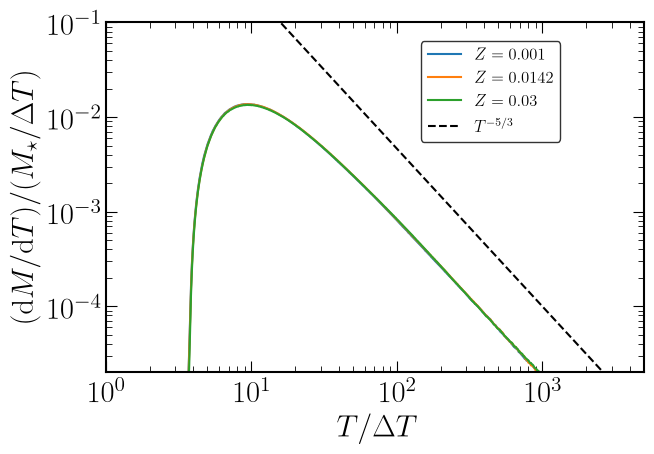

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import json
from pathlib import Path

# --------------------------------------------------
# Paths
# --------------------------------------------------

fallback_dir = Path(
    "/Users/mchau/mesa_tutorial/PerTDE/Relativistic/Fallback_Data"
)

# --------------------------------------------------
# Models
# --------------------------------------------------

models = {
    r"$Z=0.001$":  "BD40MJ_z0p0010-10GYR-m1_rp6p15",
    r"$Z=0.0142$": "BD40MJ_z0p0142-10GYR-m1_rp5p97",
    r"$Z=0.03$": "BD40MJ_z0p0300-10GYR-m1_rp5p80",
}

# --------------------------------------------------
# Load data
# --------------------------------------------------

fallback_data = {}

for label, adden in models.items():

    filename = fallback_dir / f"rel_p_t_{adden}_a0p2.txt"

    print(f"Loading: {filename}")

    with open(filename, "r") as f:
        data = json.load(f)

    fallback_data[label] = {
        k: np.array(v) for k, v in data.items()
    }

# --------------------------------------------------
# Plot
# --------------------------------------------------

plt.style.use("/Users/mchau/mesa_tutorial/PerTDE/Relativistic/plot_style.mplstyle")
plt.rc("text", usetex=True)

fig, ax = plt.subplots(figsize=(7, 5))

for label, data in fallback_data.items():
    ax.plot(
        data["x"],
        data["y"],
        label=label
    )

# T^(-5/3) reference
bins_T = np.logspace(0, 6, 200)

ax.plot(
    bins_T,
    10 * bins_T**(-5/3),
    "k--",
    label=r"$T^{-5/3}$"
)

# Axes
ax.set_xscale("log")
ax.set_yscale("log")

ax.set_xlabel(r"$T / \Delta T$")
ax.set_ylabel(r"$(\mathrm{d}M/\mathrm{d}T) / (M_\star / \Delta T)$")

ax.set_xlim(1, 5000)
ax.set_ylim(2e-5, 0.1)

ax.legend(
    loc="upper left",
    bbox_to_anchor=(0.57, 0.97),
    frameon=True,
    edgecolor="black",
    facecolor="white",
    fontsize=12
)

plt.tight_layout()
plt.show()

In [10]:
from pathlib import Path

base = Path("/Users/mchau/mesa_tutorial/results/mams_profiles")

models = {
    r"$Z=0.001$":
        base / "MAMS3Msun_Z0p0010/MAMS3Msun_Z0p0010.profile",

    r"$Z=0.0142$":
        base / "MAMS3Msun_Z0p0142/MAMS3Msun_Z0p0142.profile",

    r"$Z=0.03$":
        base / "MAMS3Msun_Z0p0300/MAMS3Msun_Z0p0300.profile",
}

for label, path in models.items():
    print(label, path)
    print("Exists:", path.exists())

$Z=0.001$ /Users/mchau/mesa_tutorial/results/mams_profiles/MAMS3Msun_Z0p0010/MAMS3Msun_Z0p0010.profile
Exists: True
$Z=0.0142$ /Users/mchau/mesa_tutorial/results/mams_profiles/MAMS3Msun_Z0p0142/MAMS3Msun_Z0p0142.profile
Exists: True
$Z=0.03$ /Users/mchau/mesa_tutorial/results/mams_profiles/MAMS3Msun_Z0p0300/MAMS3Msun_Z0p0300.profile
Exists: True


In [12]:
for label, path in paths.items():
    print(f"\n--- {label} ---")
    with open(path, "r") as f:
        for _ in range(10):
            print(f.readline().rstrip())


--- Z=0.001 ---
                                       1                                        2                                        3                                        4                                        5                                        6                                        7                                        8                                        9                                       10                                       11                                       12                                       13                                       14                                       15                                       16                                       17                                       18                                       19                                       20                                       21                                       22                                       23                                       24

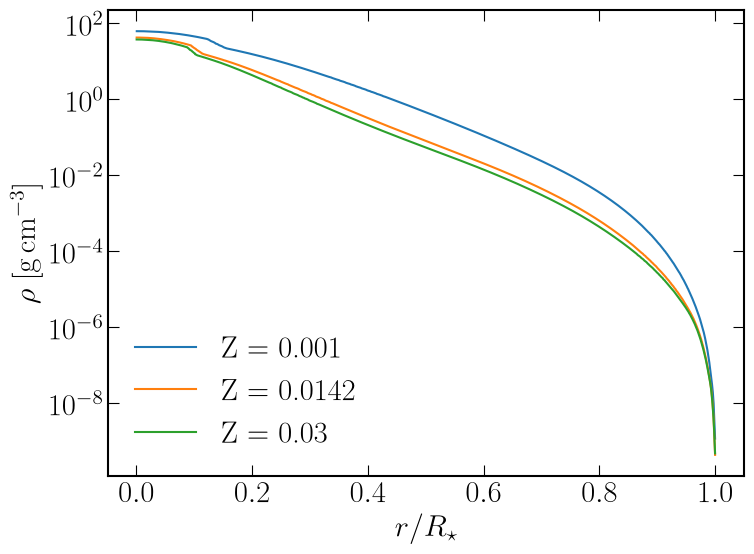

In [19]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

profiles = {
    "Z = 0.001": Path(
        "/Users/mchau/mesa_tutorial/results/mams_profiles/"
        "MAMS3Msun_Z0p0010/MAMS3Msun_Z0p0010.profile"
    ),
    "Z = 0.0142": Path(
        "/Users/mchau/mesa_tutorial/results/mams_profiles/"
        "MAMS3Msun_Z0p0142/MAMS3Msun_Z0p0142.profile"
    ),
    "Z = 0.03": Path(
        "/Users/mchau/mesa_tutorial/results/mams_profiles/"
        "MAMS3Msun_Z0p0300/MAMS3Msun_Z0p0300.profile"
    ),
}

plt.figure(figsize=(8, 6))

for label, path in profiles.items():

    # The first 3 lines are the header; line 4 starts the profile data.
    data = np.loadtxt(path, skiprows=6)

    # Columns from your profile:
    # 0 = zone
    # 1 = mass
    # 2 = logR
    # 3 = logT
    # 4 = logRho
    # 5 = logP

    r = 10**data[:, 2]
    rho = 10**data[:, 4]

    Rstar = r.max()

    plt.plot(r / Rstar, rho, label=label)

plt.yscale("log")
plt.xlabel(r"$r/R_\star$")
plt.ylabel(r"$\rho\;[\mathrm{g\,cm^{-3}}]$")
plt.legend()
plt.tight_layout()
plt.show()

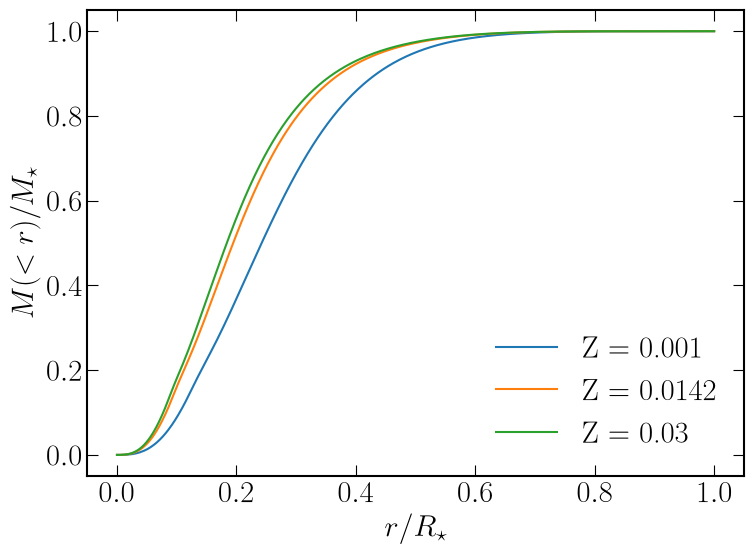

In [21]:
plt.figure(figsize=(8, 6))

for label, path in profiles.items():

    data = np.loadtxt(path, skiprows=6)

    r = 10**data[:, 2]
    m = data[:, 1]

    Rstar = r.max()
    Mstar = m.max()

    plt.plot(r / Rstar, m / Mstar, label=label)

plt.xlabel(r"$r/R_\star$")
plt.ylabel(r"$M(<r)/M_\star$")
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

profiles = {
    "Z = 0.001": Path(
        "/Users/mchau/mesa_tutorial/results/mams_profiles/"
        "MAMS3Msun_Z0p0010/MAMS3Msun_Z0p0010.profile"
    ),
    "Z = 0.0142": Path(
        "/Users/mchau/mesa_tutorial/results/mams_profiles/"
        "MAMS3Msun_Z0p0142/MAMS3Msun_Z0p0142.profile"
    ),
    "Z = 0.03": Path(
        "/Users/mchau/mesa_tutorial/results/mams_profiles/"
        "MAMS3Msun_Z0p0300/MAMS3Msun_Z0p0300.profile"
    ),
}

fig, ax = plt.subplots(figsize=(8, 6))

for label, path in profiles.items():
    data = np.loadtxt(path, skiprows=6)

    r = 10**data[:, 2]       # R/Rsun
    rho = 10**data[:, 4]     # g/cm^3

    Rstar = r.max()

    ax.plot(
        r / Rstar,
        rho,
        label=label
    )

ax.set_yscale("log")
ax.set_xlabel(r"$r/R_\star$")
ax.set_ylabel(r"$\rho\;[\mathrm{g\,cm^{-3}}]$")
ax.legend()
ax.grid(True, alpha=0.3)

# ---- CLICK POINTS ----

print("Click points on the curves.")
print("Close the plot when you're finished.")

points = plt.ginput(
    n=-1,
    timeout=0,
    show_clicks=True
)

print("\nClicked points:")
for i, (x, y) in enumerate(points, 1):
    print(f"Point {i}: r/R* = {x:.5f}, rho = {y:.5e}")

plt.show()

Click points on the curves.
Close the plot when you're finished.


/var/folders/lx/xq2x053d7d5bkpr6zt6d4d0r0000gn/T/ipykernel_3756/3395977839.py:47: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  points = plt.ginput(
